# 응용 01 · 픽셀 좌표와 YOLO 정규화 좌표 왕복

`01_coordinates.py`의 A01 구현을 실제 데이터로 확인합니다. `261104` 브랜치의 실습 문서처럼 코드 실행 → 표·시각화 → 검증 → 해석 순서로 구성했습니다.

입력은 `data/boxes_gt.csv`, 이미지 크기는 가로 160, 세로 128픽셀입니다. 이 문서는 수정된 구현의 실제 결과를 독립적으로 계산한 기준 결과와 비교합니다. 원본 Python 파일과 기존 `outputs/yolo_coordinates.csv`는 수정하지 않습니다.

프로젝트 `.venv` 등 NumPy, pandas, Matplotlib, IPython이 설치된 Python 커널에서 위에서부터 실행하세요. 실제 YOLO 모델을 실행하는 실습은 아닙니다.


In [1]:
from pathlib import Path
import io
import contextlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Image

start = Path.cwd().resolve()
project = next((p for p in [start, *start.parents]
                if (p / "20261106/02_advanced/01_coordinates.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261106/02_advanced"
assets = exercise / "docs/assets"
assets.mkdir(parents=True, exist_ok=True)
table = pd.read_csv(exercise / "data/boxes_gt.csv")
b = table[["x1", "y1", "x2", "y2"]].to_numpy(float)
width, height = 160, 128
display(table)


,image_id,class_id,x1,y1,x2,y2
0,scene,0,12,18,52,58
1,scene,1,70,60,108,98
2,scene,2,116,18,150,62


## 1. 현재 A01 구현 확인

입력 열은 `[x1, y1, x2, y2]`입니다. 수정된 코드는 `x1=b[:, 0]`, `y1=b[:, 1]`, `x2=b[:, 2]`, `y2=b[:, 3]`으로 각 열을 올바르게 배정합니다. 아래 셀은 실제 파일의 A01 블록을 읽어 실행하고, 같은 파일의 역변환 계산으로 오차를 측정합니다. 파일 전체를 실행하지 않으므로 기존 출력 CSV를 덮어쓰지 않습니다.


In [2]:
source = (exercise / "01_coordinates.py").read_text(encoding="utf-8")
a01 = source.split("# >>> A01", 1)[1].split("# <<< A01", 1)[0]
print(a01.strip())
namespace = {"np": np, "b": b.copy(), "width": width, "height": height}
exec(compile(a01, str(exercise / "01_coordinates.py"), "exec"), namespace)
current_yolo = namespace["yolo"]

def restore(yolo):
    pixel = yolo * np.array([width, height, width, height])
    return np.column_stack((pixel[:, 0] - pixel[:, 2] / 2,
                            pixel[:, 1] - pixel[:, 3] / 2,
                            pixel[:, 0] + pixel[:, 2] / 2,
                            pixel[:, 1] + pixel[:, 3] / 2))

current_restored = restore(current_yolo)
display(pd.DataFrame(current_yolo, columns=["cx", "cy", "w", "h"]))
print("현재 구현 최대 왕복 오차(px):", float(np.max(np.abs(b - current_restored))))
print("폭 또는 높이가 0 이하인 행 수:", int(np.sum(np.any(current_yolo[:, 2:] <= 0, axis=1))))


# 요구: 중심 x/y와 폭/높이를 계산하고 각 축 크기로 정규화하세요.
pass  # TODO A01: 위 요구사항의 핵심 코드를 작성하세요.
x1 = b[:, 0]
y1 = b[:, 1]
x2 = b[:, 2]
y2 = b[:, 3]

yolo = np.column_stack((
    (x1 + x2) / (2 * width),
    (y1 + y2) / (2 * height),
    (x2 - x1) / width,
    (y2 - y1) / height
))


,cx,cy,w,h
0,0.20000,0.296875,0.2500,0.312500
1,0.55625,0.617188,0.2375,0.296875
2,0.83125,0.312500,0.2125,0.343750


현재 구현 최대 왕복 오차(px): 0.0
폭 또는 높이가 0 이하인 행 수: 0


## 2. 기준 계산과 비교

`cx = (x1 + x2) / (2 × width)`, `cy = (y1 + y2) / (2 × height)`입니다. 폭은 `(x2 − x1) / width`, 높이는 `(y2 − y1) / height`입니다. `np.column_stack`은 네 배열을 열로 묶어 `(박스 수, 4)` 배열을 만듭니다.

역변환에서는 각 축 크기를 곱한 뒤 중심에서 폭·높이의 절반을 빼거나 더합니다. 정규화 좌표는 비율이며 픽셀 단위가 아닙니다.


In [3]:
x1, y1, x2, y2 = b.T
correct_yolo = np.column_stack(((x1 + x2) / (2 * width),
                                (y1 + y2) / (2 * height),
                                (x2 - x1) / width,
                                (y2 - y1) / height))
correct_restored = restore(correct_yolo)
comparison = table.copy()
comparison[["cx", "cy", "w", "h"]] = correct_yolo
comparison[["restored_x1", "restored_y1", "restored_x2", "restored_y2"]] = correct_restored
comparison["max_error_px"] = np.max(np.abs(b - correct_restored), axis=1)
display(comparison)
comparison.to_csv(assets / "01_coordinates_comparison.csv", index=False)
print("올바른 변환 최대 왕복 오차(px):", float(comparison["max_error_px"].max()))


,image_id,class_id,x1,y1,x2,y2,cx,cy,w,h,restored_x1,restored_y1,restored_x2,restored_y2,max_error_px
0,scene,0,12,18,52,58,0.20000,0.296875,0.2500,0.312500,12.0,18.0,52.0,58.0,0.0
1,scene,1,70,60,108,98,0.55625,0.617188,0.2375,0.296875,70.0,60.0,108.0,98.0,0.0
2,scene,2,116,18,150,62,0.83125,0.312500,0.2125,0.343750,116.0,18.0,150.0,62.0,0.0


올바른 변환 최대 왕복 오차(px): 0.0


## 3. 원본·수정된 구현·기준 계산 비교

동일한 좌표축과 클래스 색으로 박스를 그립니다. 채운 도형 이미지가 아니라 CSV 좌표를 그린 원리 그림입니다. 점은 좌상단, 번호는 클래스 ID입니다. 세 그림의 위치와 크기가 일치하는지 확인합니다.


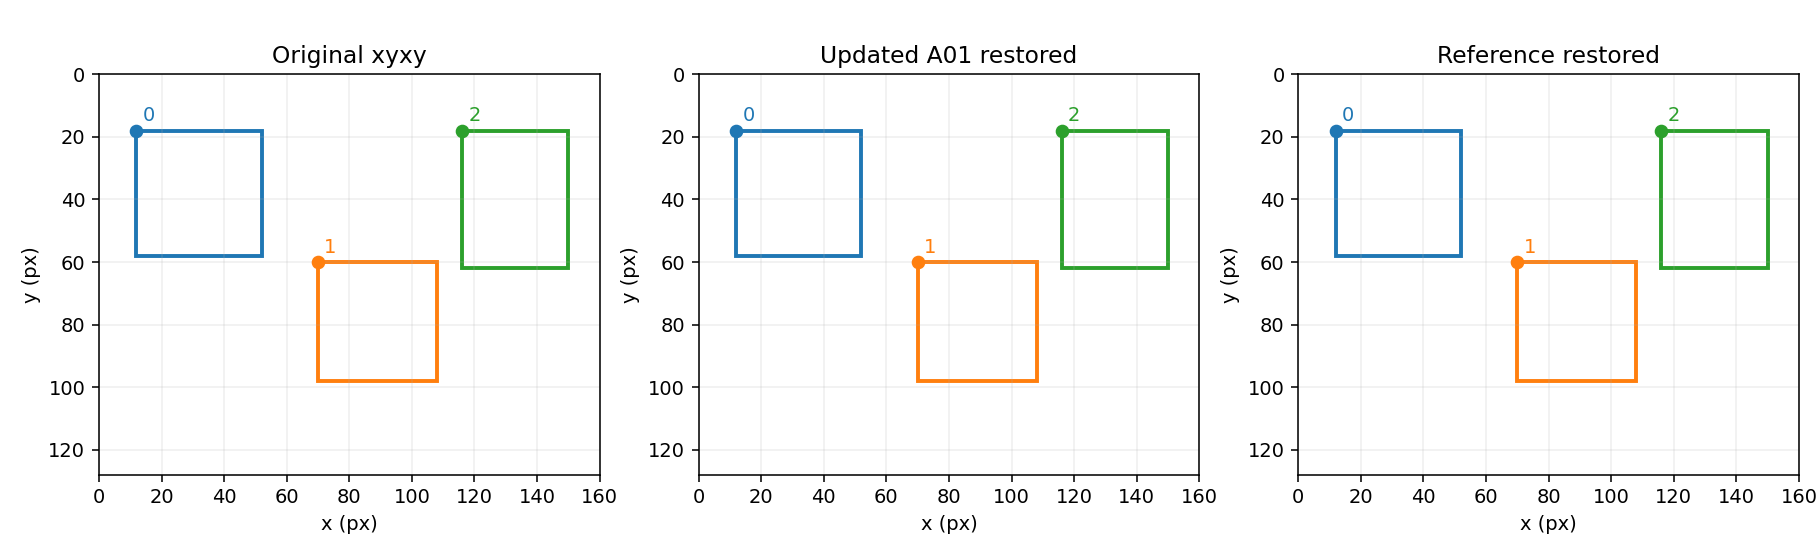

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
colors = ["tab:blue", "tab:orange", "tab:green"]
for ax, boxes, title in zip(axes, [b, current_restored, correct_restored],
                            ["Original xyxy", "Updated A01 restored", "Reference restored"]):
    for row, class_id in zip(boxes, table["class_id"]):
        left, top, right, bottom = row
        color = colors[int(class_id)]
        ax.add_patch(Rectangle((left, top), right-left, bottom-top,
                               fill=False, edgecolor=color, linewidth=2))
        ax.plot(left, top, "o", color=color)
        ax.text(left + 2, top - 3, str(class_id), color=color)
    ax.set(xlim=(0, width), ylim=(height, 0), xlabel="x (px)", ylabel="y (px)", title=title)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
fig.tight_layout()
figure_path = assets / "01_coordinates_comparison.png"
fig.savefig(figure_path, dpi=140)
plt.close(fig)
display(Image(filename=str(figure_path)))


## 4. 검증과 해석

왕복 오차만으로 모든 라벨 품질을 검증할 수는 없습니다. 여기서는 양의 폭·높이와 정규화 범위도 함께 확인합니다. 실제 이미지의 객체와 라벨이 맞는지, 클래스가 맞는지는 별도 확인이 필요합니다.


In [5]:
assert np.allclose(current_yolo, correct_yolo, atol=1e-10, rtol=0)
assert np.allclose(current_restored, b, atol=1e-10, rtol=0)
assert np.all(current_yolo[:, 2:] > 0)
assert np.all((current_yolo >= 0) & (current_yolo <= 1))
assert np.allclose(correct_restored, b, atol=1e-10, rtol=0)
assert np.all(correct_yolo[:, 2:] > 0)
assert np.all((correct_yolo >= 0) & (correct_yolo <= 1))
assert np.allclose(correct_yolo[0], [0.2, 0.296875, 0.25, 0.3125])
print("검증 통과: 왕복 좌표 일치 · 양의 폭/높이 · 정규화 범위 · 첫 박스 손계산 일치")


검증 통과: 왕복 좌표 일치 · 양의 폭/높이 · 정규화 범위 · 첫 박스 손계산 일치


입력 좌표와 이미지 크기를 고정하고, 수정된 A01 구현을 독립적인 기준 계산과 비교했습니다. 수정된 구현과 기준 계산 모두 최대 왕복 오차는 0픽셀이고, 폭·높이가 0 이하인 박스는 없습니다. 원본과 복원 좌표의 위치·크기도 일치합니다.

`x2`와 `y1`의 열 배정이 바로잡혀 중심 좌표와 폭·높이가 올바르게 계산됩니다. 예를 들어 첫 박스 `[12, 18, 52, 58]`은 정규화 좌표 `[0.2, 0.296875, 0.25, 0.3125]`가 됩니다. 가로·세로 크기가 다른 이미지이므로 x·폭은 160, y·높이는 128로 나눕니다.

실행 결과 표와 비교 그림은 이 문서에 포함되어 있으며 `docs/assets/`에도 저장됩니다. 좌표 변환 성공은 실제 YOLO 학습·추론 성능을 의미하지 않습니다.
